In [1]:
# !find /notebooks -name "*.zip"
# !unzip /notebooks/dataset_semantic.zip -d /notebooks/dataset_semantic

In [2]:
!rm -rf /notebooks/.Trash-0

# Main Configuration

In [3]:
CFG_DICT = {
    "system": {
        "env": "PAPERSPACE",        # Options: "COLAB", "PAPERSPACE"
        "seed": 42,
        "project_name": "Forest_3D_Semantic",
        "exp_name": "SpConv_v1",
        "dataset_dir": "/notebooks/dataset_semantic",
        "output_dir": "/notebooks/semantic_segmentation_results",
    },
    
    "dataset": {
        "semantic_attr": "classification_mapped",
        "target_density": 50.0,
        "max_points": 25000,
        "patch_size": 20,
        "splits": {
            "train": "train", # Can be a string "train" or a list ["train", "train_synth"]
            "val": "val",
            "test": "test"
        },
        "class_names": {
            "background": 0,
            "trunk": 1,
            "tree_crown": 2
        },
        "color_map": {
            0: "gray",
            1: "saddlebrown",
            2: "forestgreen"
        }
    },

    "model": {
        "active": "SpConv",         # Selection: "PointNetPP", "PointNext", "SpConv", "PTv3"
        "architectures": {
            "PointNetPP": {
                "in_channels": 3,
                "feat_dim": 32,
                "num_classes": 3
            },
            "PointNext": {
                "in_channels": 3,
                "feat_dim": 32,
                "num_classes": 3,
                "initial_radius": 0.1,
                "k_neighbors": 32
            },
            "SpConv": {
                "in_channels": 3,
                "feat_dim": 32,
                "num_classes": 3,
                "voxel_size": 0.05
            },
            "PTv3": {
                "in_channels": 3,
                "feat_dim": 32,
                "num_classes": 3,
                "patch_size": 20
            }
        }
    },

    "train": {
        "batch_size": 8,            # Recommended: SpConv=8, PTv3=2
        "epochs": 20,
        "warmup_epochs": 5,
        "primary_metric": "val/mIoU",
        "resume": False,
        "path_to_ckpt": None
    },

    "optimizer": {
        "name": "AdamW",
        "lr": 1e-4,
        "weight_decay": 1e-4,
        "scheduler": {
            "name": "CosineAnnealingLR",
            "eta_min": 1e-6
        }
    },

    "loss": {
        "name": "DiceFocalLoss",
        "params": {
            "gamma": 2.5,
            "dice_weight": 0.5,
            "label_smoothing": 0.15
        }
    },

    "logging": {
        "logger": "wandb",          # Options: "wandb", "tensorboard"
        "wandb_api_key": None,
        "vis_freq": 1,
        "num_vis": 3,
    },
    
    "augmentation": {
        "rotate_deg": 360,
        "flip_p": 0.5,
        "scale_range": (0.8, 1.2),
        "anisotropic_p": 0.5,
        "node_drop_p": 0.1,
        "density_change": {
            "trunk": {"radius": 2.0, "factor": 0.2, "p": 0.1},
            "crown": {"radius": 3.0, "factor": 0.2, "p": 0.1}
        },
        "slope_max_angle": 20,
        "slope_p": 0.1,
        "thickener": {"factor": 1.5, "jitter": 0.01, "p": 0.1},
        "stem_stretch": {"range": (0.7, 1.4), "p": 0.1},
        "elastic_distortion": (0.05, 0.05, 0.05)
    },
    
    "metrics": {
        "iou": {"name": "MulticlassJaccardIndex", "params": {"average": None}},
        "f1":  {"name": "MulticlassF1Score", "params": {"average": "macro"}}
    }
}

# Dynamic System Setup

In [4]:
import os

if CFG_DICT["system"]["env"] == "COLAB":
    print("Environment: COLAB. Starting full system provisioning...")

    # 1.1 Mount Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # 1.2 Data Provisioning (Hardcoded paths)
    print("Copying and unzipping dataset...")
    # Copy from Drive to local SSD
    get_ipython().system("cp -r /content/drive/MyDrive/dataset.zip /content/")

    # Unzip locally
    get_ipython().system("unzip -q -n /content/dataset.zip -d /content/dataset_semantic/")

    # 1.3 Torch Overhaul (Reinstall for CUDA 12.4)
    print("Reinstalling PyTorch for CUDA 12.4 compatibility...")
    get_ipython().system("pip uninstall torch torchvision torchaudio -y")
    get_ipython().system("pip install -q torch==2.5.1+cu124 torchvision==0.20.1+cu124 torchaudio==2.5.1+cu124 --index-url https://download.pytorch.org/whl/cu124")

    # 1.4 Get Torch Version for PyG wheels
    import torch
    torch_version = torch.__version__
    os.environ['TORCH'] = torch_version
    print(f"PyTorch version: {torch_version}")

    # 1.5 PyTorch Geometric and Dependencies
    print("Installing PyTorch Geometric and wheels...")
    get_ipython().system(f"pip install -q torch-scatter -f https://data.pyg.org/whl/torch-{torch_version}.html")
    get_ipython().system(f"pip install -q torch-sparse -f https://data.pyg.org/whl/torch-{torch_version}.html")
    get_ipython().system(f"pip install -q torch-cluster -f https://data.pyg.org/whl/torch-{torch_version}.html")
    get_ipython().system("pip install -q git+https://github.com/pyg-team/pytorch_geometric.git")

    # 1.6 Additional Utilities
    print("Installing remaining utilities (wandb, laspy, metrics)...")
    get_ipython().system("pip install -q torchmetrics laspy[lazrs] wandb seaborn")


print("System setup completed.")

System setup completed.


# Imports

In [5]:
# ==========================================================
# 1. STANDARD LIBRARY & SYSTEM
# ==========================================================
import os
import math
import random
import shutil
import sys
import datetime
from glob import glob
from collections import Counter
from types import SimpleNamespace

# ==========================================================
# 2. DATA PROCESSING & UTILS
# ==========================================================
import numpy as np
import laspy
from tqdm.notebook import tqdm
from PIL import Image

# ==========================================================
# 3. PYTORCH CORE
# ==========================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor
from torch.nn import Sequential as Seq, Linear, ReLU, BatchNorm1d as BN
from torch.utils.data import ConcatDataset

# ==========================================================
# 4. PYTORCH GEOMETRIC (PyG)
# ==========================================================
from torch_geometric.data import Data, InMemoryDataset
from torch_geometric.loader import DataLoader
import torch_geometric.transforms as T
from torch_geometric.transforms import BaseTransform
from torch_scatter import scatter, scatter_mean

# ==========================================================
# 5. METRICS & EVALUATION
# ==========================================================
import torchmetrics
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassJaccardIndex,
    MulticlassF1Score,
    MulticlassPrecision,
    MulticlassRecall
)
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================================
# 6. LOGGING & VISUALIZATION
# ==========================================================
import wandb
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb
from mpl_toolkits.mplot3d import Axes3D

from torch.optim.lr_scheduler import LinearLR, SequentialLR
import torch.optim.lr_scheduler as lr_scheduler

# ==========================================================
# 7. SPCONV
# ==========================================================
try:
    import spconv.pytorch as spconv
    SPCONV_AVAILABLE = True
    print("SpConv: LOADED (Backend: spconv.pytorch)")
except ImportError:
    SPCONV_AVAILABLE = False
    print("SpConv: NOT FOUND")

# ==========================================================
# 8. POINT TRANSFORMER V3
# ==========================================================
sys.path = [p for p in sys.path if "PTv3" not in p]

if "/notebooks" not in sys.path:
    sys.path.insert(0, "/notebooks")

get_ipython().system("touch /notebooks/PTv3_Standalone/__init__.py")

try:
    from PTv3_Standalone.model import PointTransformerV3
    PTv3_AVAILABLE = True
    print("PTv3: LOADED (Success via Package Path!)")
except Exception as e:
    PTv3_AVAILABLE = False
    print(f"PTv3 ERROR: {e}")


SpConv: LOADED (Backend: spconv.pytorch)


/notebooks/miniconda/envs/treeseg/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


PTv3: LOADED (Success via Package Path!)


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [7]:
get_ipython().system("find /notebooks/Pointcept -name '*transformer_v3*'")

In [8]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Engine

## Config Setup

In [9]:
def dict_to_obj(d):
    """
    Recursively converts dictionary to SimpleNamespace, 
    """
    if isinstance(d, dict):
        if all(isinstance(k, str) for k in d.keys()):
            return SimpleNamespace(**{k: dict_to_obj(v) for k, v in d.items()})
        else:
            # If keys are ints (like color_map), keep it as a regular dict
            return {k: dict_to_obj(v) for k, v in d.items()}
    return d

## Dataset

In [10]:
class ForestLAZSemanticDataset(InMemoryDataset):
    def __init__(
        self,
        root_dir,
        split="train",
        transform=None,
        pre_transform=None,
        pre_filter=None,
    ):
        assert split in ["train", "train_synth", "val", "test"]
        self.split = split

        super().__init__(os.path.join(root_dir, split), transform, pre_transform, pre_filter)

        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_dir(self):
        return self.root

    @property
    def processed_dir(self):
        return os.path.join(self.root, "processed")

    @property
    def raw_file_names(self):
        all_files = glob(os.path.join(self.raw_dir, "*.laz")) + glob(os.path.join(self.raw_dir, "*.las"))
        return sorted([os.path.basename(p) for p in all_files])

    @property
    def processed_file_names(self):
        return "data.pt"

    def process(self):
        data_list = []
        if not self.raw_file_names:
            raise FileNotFoundError(f"No .laz/.las files in {self.raw_dir}")

        print(f"--- Start processing: {len(self.raw_file_names)} files ({self.split}) ---")

        for raw_path_str in self.raw_paths:
            try:
                filename = os.path.basename(raw_path_str)
                
                las = laspy.read(raw_path_str)
                positions = np.vstack((las.x, las.y, las.z)).T
                positions -= positions.min(axis=0)
                labels = np.array(las[CFG.dataset.semantic_attr])

                data = Data(
                    pos=torch.from_numpy(positions).to(torch.float),
                    y=torch.from_numpy(labels).to(torch.long),
                    filename=filename 
                )

                if self.pre_transform is not None:
                    data = self.pre_transform(data)

                data_list.append(data)

            except Exception as e:
                print(f"Error in file {raw_path_str}: {e}")

        if not data_list:
            print("Warning: No processed files.")
            return

        # Collate and save
        data, slices = self.collate(data_list)
        os.makedirs(self.processed_dir, exist_ok=True)
        torch.save((data, slices), self.processed_paths[0])
        print(f"--- Finished! File saved as: {self.processed_paths[0]} ---")

    @property
    def num_classes(self):
        if hasattr(CFG.dataset.class_names, "__dict__"):
            return len(vars(CFG.dataset.class_names))
        return len(CFG.dataset.class_names)

In [11]:
def create_train_dataset(cfg, transform=None):

    train_folders = cfg.dataset.splits.train
    
    if isinstance(train_folders, list):
        print(f"Loading multiple training sources: {train_folders}")
        datasets = []
        for folder in train_folders:
            ds = ForestLAZSemanticDataset(
                root_dir=cfg.system.dataset_dir,
                split=folder,
                transform=transform
            )
            datasets.append(ds)
        return ConcatDataset(datasets)
    
    else:
        print(f"Loading single training source: {train_folders}")
        return ForestLAZSemanticDataset(
            root_dir=cfg.system.dataset_dir,
            split=train_folders,
            transform=transform
        )

## Transformations

In [12]:
class NormalizePositions(BaseTransform):
    def __init__(self, patch_size=20.0):
        super().__init__()
        self.patch_size = patch_size
        self.fixed_scale = patch_size / 2

    def forward(self, data: Data) -> Data:
        pos = data.pos.clone()

        min_z = pos[:, 2].min()
        pos[:, 2] -= min_z

        center_xy = pos[:, :2].mean(dim=0)
        pos[:, :2] -= center_xy

        pos /= self.fixed_scale

        data.pos = pos
        # only raw geometry as data features
        data.x = pos.clone()

        return data

In [13]:
class AreaBasedSampler(BaseTransform):
    """
    """
    def __init__(
        self,
        target_density: float = 50.0, # ile punktów na m2
        area_grid_res: float = 0.5,   # rozdzielczość siatki do liczenia pola
        max_points: int = 50000,
        min_points: int = 1024
    ):
        super().__init__()
        self.target_density = target_density
        self.area_grid_res = area_grid_res
        self.max_points = max_points
        self.min_points = min_points

    def _estimate_area(self, pos):
        xy = pos[:, :2]
        xy_min = xy.min(dim=0)[0]


        grid_coords = torch.floor((xy - xy_min) / self.area_grid_res).to(torch.long)
        grid_ids = grid_coords[:, 0] + grid_coords[:, 1] * (grid_coords[:, 0].max() + 1)
        num_occupied_cells = torch.unique(grid_ids).size(0)

        actual_area = num_occupied_cells * (self.area_grid_res ** 2)
        return max(actual_area, 1e-4)

    def forward(self, data: Data) -> Data:
        pos = data.pos
        num_nodes = pos.size(0)

        area = self._estimate_area(pos)
        target_num = int(area * self.target_density)
        target_num = max(min(target_num, self.max_points), self.min_points)

        if num_nodes >= target_num:
            # Downsampling:
            choice = torch.randperm(num_nodes, device=pos.device)[:target_num]
        else:
            # Upsampling
            extra_idx = torch.randint(0, num_nodes, (target_num - num_nodes,), device=pos.device)
            choice = torch.cat([torch.arange(num_nodes, device=pos.device), extra_idx])

        for key, item in data:
            if torch.is_tensor(item) and item.size(0) == num_nodes:
                data[key] = item[choice]

        return data

In [14]:
class OneOf(BaseTransform):
    """Randomly selects and applies exactly one transform from the provided list."""
    def __init__(self, transforms, p=None):
        super().__init__()
        self.transforms = transforms
        self.p = p if p is not None else [1.0 / len(transforms)] * len(transforms)

    def forward(self, data: Data) -> Data:
        t = random.choices(self.transforms, weights=self.p, k=1)[0]
        return t(data)

class RandomSlope(BaseTransform):
    """Simulates sloped terrain by tilting the Z-coordinates relative to XY plane."""
    def __init__(self, max_angle_deg=15, p=0.5):
        super().__init__()
        self.max_angle_deg = max_angle_deg
        self.p = p

    def forward(self, data: Data) -> Data:
        if random.random() > self.p: return data
        pos = data.pos
        max_slope = math.tan(math.radians(self.max_angle_deg))
        slope_x, slope_y = [random.uniform(-max_slope, max_slope) for _ in range(2)]
        x_c, y_c = (pos[:, 0].max() + pos[:, 0].min())/2, (pos[:, 1].max() + pos[:, 1].min())/2
        data.pos[:, 2] += slope_x * (pos[:, 0] - x_c) + slope_y * (pos[:, 1] - y_c)
        return data

class RandomElasticDistortion(BaseTransform):
    """Applies non-linear spatial warping using smoothed 3D noise."""
    def __init__(self, granularity=(0.2, 0.2, 0.2), magnitude=(0.1, 0.1, 0.1)):
        super().__init__()
        self.granularity, self.magnitude = torch.tensor(granularity), torch.tensor(magnitude)

    def forward(self, data: Data) -> Data:
        if data.pos is None: return data
        device = data.pos.device
        noise = (torch.rand(1, 3, 5, 5, 5, device=device) - 0.5) * 2
        noise = torch.nn.functional.conv_transpose3d(noise, torch.ones((1,1,3,3,3), device=device).repeat(3,1,1,1,1)/27.0, stride=2, groups=3).permute(0,2,3,4,1).squeeze(0)
        p_min, p_max = data.pos.min(0)[0], data.pos.max(0)[0]
        p_norm = (data.pos - p_min) / (p_max - p_min + 1e-8)
        idx = (p_norm * torch.tensor(noise.shape[:3], device=device) - 0.5).long().clamp(min=0)
        dist = noise[idx[:,0].clamp(max=noise.shape[0]-1), idx[:,1].clamp(max=noise.shape[1]-1), idx[:,2].clamp(max=noise.shape[2]-1)]
        data.pos += dist * (p_max - p_min) * self.magnitude.to(device)
        return data

class ForestGeometryThickener(BaseTransform):
    """Upsamples specific classes by duplicating points with random jitter."""
    def __init__(self, upsample_factor: float = 2.0, jitter_std: float = 0.01, target_class_ids: list = [1], p: float = 0.5):
        super().__init__()
        self.upsample_factor, self.jitter_std, self.target_class_ids, self.p = upsample_factor, jitter_std, target_class_ids, p

    def forward(self, data: Data) -> Data:
        if torch.rand(1) > self.p or not hasattr(data, 'y'): return data
        mask = torch.zeros(data.pos.size(0), dtype=torch.bool, device=data.pos.device)
        for cid in self.target_class_ids: mask |= (data.y == cid)
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() == 0: return data
        num_add = int(indices.numel() * (self.upsample_factor - 1.0))
        if num_add <= 0: return data
        chosen = indices[torch.randint(0, indices.numel(), (num_add,))]
        new_pos = data.pos[chosen] + torch.randn((num_add, 3), device=data.pos.device) * self.jitter_std
        old_num = data.pos.size(0)
        data.pos = torch.cat([data.pos, new_pos], dim=0)
        for key in list(data.keys()):
            if key == 'pos': continue
            item = getattr(data, key)
            if torch.is_tensor(item) and item.size(0) == old_num:
                setattr(data, key, torch.cat([item, item[chosen]], dim=0))
        return data

class ClassLocalDensityChange(BaseTransform):
    """
    Randomly reduces point density within a spherical region for a specific class.
    Robust version: handles cases with 0 or 1 point in the sphere.
    """
    def __init__(self, target_class_id: int, radius: float = 2.0, factor: float = 0.2, p: float = 0.5):
        super().__init__()
        self.target_class_id = target_class_id
        self.radius = radius
        self.factor = factor
        self.p = p

    def forward(self, data: Data) -> Data:
        if torch.rand(1) > self.p or not hasattr(data, 'y'): return data
        pos, labels = data.pos, data.y

        # Get indices of the target class
        class_mask = (labels == self.target_class_id)
        indices = class_mask.nonzero().view(-1) # Use view(-1) to keep it as a vector

        if indices.numel() == 0: return data

        # Pick a random center point from the target class
        center_idx = indices[torch.randint(0, indices.numel(), (1,))].item()
        center = pos[center_idx]

        # Find points of target class within radius
        dist = torch.norm(pos - center, dim=1)
        in_sphere_mask = (dist <= self.radius) & class_mask
        other_mask = ~in_sphere_mask

        # Get indices of points to be processed
        target_idx = in_sphere_mask.nonzero().view(-1) # SAFE: ensures vector even for 1 point

        if target_idx.numel() > 0:
            # Calculate how many to keep
            keep_num = max(1, int(target_idx.numel() * self.factor))

            # Randomly select subset to keep
            perm = torch.randperm(target_idx.numel(), device=pos.device)
            keep_idx = target_idx[perm[:keep_num]]

            # Combine kept points with everything else
            final_mask = torch.zeros(pos.size(0), dtype=torch.bool, device=pos.device)
            final_mask[other_mask] = True
            final_mask[keep_idx] = True

            # Apply mask to all attributes
            for key in list(data.keys()):
                item = getattr(data, key)
                if torch.is_tensor(item) and item.size(0) == pos.size(0):
                    setattr(data, key, item[final_mask])

        return data
    
    
class RandomAnisotropicScale(BaseTransform):
    """
    Scales X and Y axes independently. 
    Makes trees look thinner or wider without changing their height.
    """
    def __init__(self, scale_range=(0.8, 1.2), p=0.5):
        super().__init__()
        self.scale_range = scale_range
        self.p = p

    def forward(self, data: Data) -> Data:
        if random.random() > self.p:
            return data
        
        # Independent scale factors for X and Y
        sx = random.uniform(self.scale_range[0], self.scale_range[1])
        sy = random.uniform(self.scale_range[0], self.scale_range[1])
        
        data.pos[:, 0] *= sx
        data.pos[:, 1] *= sy
        
        # Update features if they contain XYZ
        if data.x is not None and data.x.size(-1) >= 3:
            data.x[:, 0] *= sx
            data.x[:, 1] *= sy
            
        return data

class SemanticStemStretch(BaseTransform):
    """
    Stretches only the points belonging to the stem class along the Z axis.
    """
    def __init__(self, stem_id=1, stretch_range=(0.8, 1.3), p=0.5):
        super().__init__()
        self.stem_id = stem_id
        self.stretch_range = stretch_range
        self.p = p

    def forward(self, data: Data) -> Data:
        if random.random() > self.p or not hasattr(data, 'y'):
            return data
        
        stem_mask = (data.y == self.stem_id)
        if not stem_mask.any():
            return data
            
        # Random vertical stretch factor
        s = random.uniform(self.stretch_range[0], self.stretch_range[1])
        
        # Find base Z of the stem to stretch upwards
        min_z = data.pos[stem_mask, 2].min()
        
        # Apply stretch relative to base
        data.pos[stem_mask, 2] = (data.pos[stem_mask, 2] - min_z) * s + min_z
        
        # If crown is above the stem, we need to shift it up as well 
        # to prevent stem-crown separation
        crown_mask = (data.y != self.stem_id) & (data.y != 0) # Assumes 0 is ground
        if crown_mask.any():
            # Shift crown by the difference in stem height
            max_z_before = data.pos[stem_mask, 2].max()
            # (already updated, so we need original shift)
            # simplest way: just shift everything above min_z
            shift = (s - 1.0) * (data.pos[stem_mask, 2].max() - min_z)
            data.pos[crown_mask, 2] += shift

        return data
    
    
class RandomNodeDrop(BaseTransform):
    """
    Randomly drops a percentage of points from the cloud.
    Acts as a strong regularizer (Data Dropout) to prevent overfitting.
    """
    def __init__(self, p=0.1):
        super().__init__()
        self.p = p

    def forward(self, data: Data) -> Data:
        num_nodes = data.num_nodes
        # Create a mask where True = keep point, False = drop point
        mask = torch.rand(num_nodes) > self.p
        
        # If all points are kept, just return original data
        if mask.all():
            return data

        # Apply mask to all point-wise attributes
        for key in list(data.keys()):
            item = getattr(data, key)
            if torch.is_tensor(item) and item.size(0) == num_nodes:
                setattr(data, key, item[mask])
                
        return data

## Class Weights

In [15]:
def calculate_class_weights(dataset):
    """
    Computes inverse frequency weights. 
    Handles both single and ConcatDatasets.
    """
    print("Calculating class weights from dataset...")

    # Handle ConcatDataset or single Dataset
    if hasattr(dataset, 'datasets'):
        all_labels = torch.cat([ds._data.y for ds in dataset.datasets]).numpy()
    else:
        all_labels = dataset._data.y.numpy()

    counts = Counter(all_labels)
    total_points = len(all_labels)
    
    if isinstance(CFG.dataset.class_names, dict):
        num_classes = len(CFG.dataset.class_names)
    else:
        num_classes = len(vars(CFG.dataset.class_names))

    # Calculate weights
    weights = []
    for i in range(num_classes):
        count = counts.get(i, 0)
        if count > 0:
            weight = total_points / (num_classes * count)
        else:
            weight = 1.0
        weights.append(weight)

    return torch.tensor(weights, dtype=torch.float).to(device)

## Architecture

### Custom FPS & KNN

In [16]:
def custom_fps(pos, batch, ratio):
    """Pure PyTorch Farthest Point Sampling (Batch-aware)."""
    indices = []
    for b in torch.unique(batch):
        mask = (batch == b)
        cloud_pos = pos[mask]
        cloud_indices = torch.where(mask)[0]
        num_points = cloud_pos.size(0)
        num_samples = max(1, int(num_points * ratio))
        selected_idx = torch.zeros(num_samples, dtype=torch.long, device=pos.device)
        distances = torch.ones(num_points, device=pos.device) * 1e10
        farthest = 0
        for i in range(num_samples):
            selected_idx[i] = farthest
            centroid = cloud_pos[farthest].view(1, 3)
            dist = torch.sum((cloud_pos - centroid) ** 2, dim=-1)
            distances = torch.min(distances, dist)
            farthest = torch.argmax(distances)
        indices.append(cloud_indices[selected_idx])
    return torch.cat(indices)

def custom_knn(x, y, k, batch_x, batch_y):
    """Pure PyTorch k-Nearest Neighbors (Batch-aware)."""
    row_list, col_list = [], []
    for b in torch.unique(batch_x):
        mask_x, mask_y = (batch_x == b), (batch_y == b)
        x_b, y_b = x[mask_x], y[mask_y]
        idx_x, idx_y = torch.where(mask_x)[0], torch.where(mask_y)[0]

        # Compute distance matrix [num_y, num_x]
        dist = torch.cdist(y_b, x_b)

        # Get k nearest neighbors
        _, k_indices = torch.topk(dist, k=k, dim=-1, largest=False)

        # row: indices in y (sampled points), col: indices in x (all points)
        row = torch.arange(y_b.size(0), device=x.device).view(-1, 1).repeat(1, k).view(-1)
        col = k_indices.view(-1)

        row_list.append(idx_y[row])
        col_list.append(idx_x[col])

    return torch.stack([torch.cat(row_list), torch.cat(col_list)], dim=0)

def custom_knn_interpolate(x, pos_coarse, pos_fine, batch_coarse, batch_fine, k=3):
    """Pure PyTorch Inverse Distance Weighting interpolation."""
    # Find 3 nearest neighbors in coarse cloud for each point in fine cloud
    edge_index = custom_knn(pos_coarse, pos_fine, k, batch_coarse, batch_fine)
    row, col = edge_index

    # Calculate distances
    dist = torch.sum((pos_fine[row] - pos_coarse[col])**2, dim=-1).sqrt()
    dist = torch.clamp(dist, min=1e-10)
    weight = 1.0 / dist

    # Weighted average of features
    # row: destination index, col: source index, x[col]: source features
    from torch_scatter import scatter
    weighted_features = x[col] * weight.view(-1, 1)
    sum_weights = scatter(weight, row, dim=0, dim_size=pos_fine.size(0), reduce='sum').view(-1, 1)
    out = scatter(weighted_features, row, dim=0, dim_size=pos_fine.size(0), reduce='sum')

    return out / sum_weights

### Semantic head

In [17]:
class SemanticHead(nn.Module):
    """
    Point-wise Semantic Classification Head.
    Maps high-dimensional latent features to raw semantic scores (logits).
    """
    def __init__(
        self,
        in_dim: int = 128,
        num_classes: int = 3
    ) -> None:
        super().__init__()

        # Multi-layer perceptron for per-point classification
        self.mlp = nn.Sequential(
            Linear(in_dim, 128),
            BN(128),
            ReLU(inplace=True),
            nn.Dropout(0.1),  # Added for better generalization
            Linear(128, num_classes)
        )

    def forward(self, features: Tensor) -> Tensor:
        """
        Input: [N_points, in_dim] - High-level features from the backbone.
        Output: [N_points, num_classes] - Raw logits for CrossEntropyLoss.
        """
        return self.mlp(features)

### Pointnet++ Based Model

#### Backbone

In [18]:
def MLP(channels, batch_norm=True, last_act=True):
    """
    Constructs an MLP sequence.
    Technical flags have defaults to keep the backbone code clean.
    """
    layers = []
    for i in range(1, len(channels)):
        layers.append(Linear(channels[i - 1], channels[i]))
        if batch_norm:
            layers.append(BN(channels[i]))
        if (i < len(channels) - 1) or last_act:
            layers.append(ReLU(inplace=True))
    return Seq(*layers)

class SharedMLP(nn.Module):
    """
    Point-wise MLP. Default flags are set for common use cases.
    """
    def __init__(self, channels, batch_norm=True, dropout=0.0, last_act=True):
        super().__init__()
        self.mlp = MLP(channels, batch_norm, last_act)
        self.drop = nn.Dropout(dropout) if dropout > 0 else None

    def forward(self, x):
        x = self.mlp(x)
        if self.drop is not None:
            x = self.drop(x)
        return x

In [19]:
class SAModule(nn.Module):
    def __init__(self, ratio, k, nn_module):
        super().__init__()
        self.ratio = ratio
        self.k = k
        self.conv = nn_module

    def forward(self, x, pos, batch):
        # Using custom implementations
        idx = custom_fps(pos, batch, ratio=self.ratio)
        edge_index = custom_knn(pos, pos[idx], self.k, batch, batch[idx])
        row, col = edge_index

        x_group = scatter(x[col], row, dim=0, dim_size=idx.size(0), reduce='max')
        x_out = self.conv(x_group)
        return x_out, pos[idx], batch[idx]

class FPModule(nn.Module):
    def __init__(self, k, in_channels, mlp_channels):
        super().__init__()
        self.k = k
        self.mlp = SharedMLP([in_channels] + mlp_channels)

    def forward(self, x_coarse, pos_coarse, batch_coarse, x_skip, pos_skip, batch_skip):
        # Using custom interpolation
        x_interp = custom_knn_interpolate(
            x_coarse, pos_coarse, pos_skip,
            batch_coarse, batch_skip, k=self.k
        )

        # Skip connection & MLP
        x_out = torch.cat([x_interp, x_skip], dim=1) if x_skip is not None else x_interp
        return self.mlp(x_out), pos_skip, batch_skip

In [20]:
class PointNet2Backbone(nn.Module):
    def __init__(self, in_channels, feat_dim):
        super().__init__()

        self.sa1 = SAModule(0.5, 32, SharedMLP([in_channels, 64, 128]))
        self.sa2 = SAModule(0.25, 48, SharedMLP([128, 256, 256]))
        self.sa3 = SAModule(0.1, 64, SharedMLP([256, 512, 512]))

        self.fp3 = FPModule(3, 512 + 256, [512, 256])
        self.fp2 = FPModule(3, 256 + 128, [256, 128])
        self.fp1 = FPModule(3, 128 + in_channels, [256, feat_dim])

    def forward(self, x, pos, batch):
        l1_x, l1_pos, l1_batch = self.sa1(x, pos, batch)
        l2_x, l2_pos, l2_batch = self.sa2(l1_x, l1_pos, l1_batch)
        l3_x, l3_pos, l3_batch = self.sa3(l2_x, l2_pos, l2_batch)

        l2_x_up, _, _ = self.fp3(l3_x, l3_pos, l3_batch, l2_x, l2_pos, l2_batch)
        l1_x_up, _, _ = self.fp2(l2_x_up, l2_pos, l2_batch, l1_x, l1_pos, l1_batch)
        l0_x_up, _, _ = self.fp1(l1_x_up, l1_pos, l1_batch, x, pos, batch)

        return l0_x_up

#### Model

In [21]:
class PointNetPPModel(nn.Module):
    """
    Full Semantic Segmentation Model (Encoder).
    Combines PointNet2 Backbone with the Semantic Classification Head.
    """
    def __init__(self, in_channels, feat_dim, num_classes):
        super().__init__()

        # Initialize internal backbone
        self.backbone = PointNet2Backbone(in_channels, feat_dim)

        # Initialize internal semantic head (using your existing SemanticHead class)
        self.sem_head = SemanticHead(feat_dim, num_classes)

    def forward(self, data):
        # Extract basic data from PyG object
        pos, x, batch = data.pos, data.x, data.batch

        # Fallback to positions as features if x is not present
        if x is None:
            x = pos

        # 1. Feature Extraction via Backbone
        point_features = self.backbone(x, pos, batch)

        # 2. Per-point classification via Semantic Head
        logits = self.sem_head(point_features)

        return logits

### PointNext

#### Backbone

In [22]:
class InvertedResidual(nn.Module):
    """PointNeXt Bottleneck Block: Expansion -> Activation -> Reduction + Residual."""
    def __init__(self, in_channels, out_channels, expansion=4):
        super().__init__()
        mid_channels = in_channels * expansion
        self.mlp = nn.Sequential(
            nn.Linear(in_channels, mid_channels),
            nn.BatchNorm1d(mid_channels),
            nn.GELU(),
            nn.Linear(mid_channels, out_channels),
            nn.BatchNorm1d(out_channels)
        )
        self.shortcut = nn.Identity() if in_channels == out_channels else \
                        nn.Sequential(nn.Linear(in_channels, out_channels), nn.BatchNorm1d(out_channels))

    def forward(self, x):
        return self.mlp(x) + self.shortcut(x)

class SetAbstractionNeXt(nn.Module):
    """Hierarchical Downsampling with Local Geometry Embedding (LGE)."""
    def __init__(self, ratio, k, radius_val, in_channels, out_channels, num_blocks):
        super().__init__()
        self.ratio, self.k, self.radius_val = ratio, k, radius_val
        self.pos_embed_dim = max(16, min(out_channels // 4, 128))

        self.pos_embed = nn.Sequential(
            nn.Linear(3, self.pos_embed_dim),
            nn.GroupNorm(4, self.pos_embed_dim),
            nn.GELU(),
            nn.Linear(self.pos_embed_dim, self.pos_embed_dim)
        )

        self.mlp_in = (in_channels - 3) + self.pos_embed_dim if in_channels > 3 else self.pos_embed_dim
        self.conv_in = nn.Sequential(
            nn.Linear(self.mlp_in, out_channels),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )
        self.blocks = nn.Sequential(*[InvertedResidual(out_channels, out_channels) for _ in range(num_blocks)])

    def forward(self, x, pos, batch):
        # Using your custom robust FPS
        idx = custom_fps(pos, batch, ratio=self.ratio)

        # Using custom KNN (more stable than radius search for fixed batch sizes)
        edge_index = custom_knn(pos, pos[idx], self.k, batch, batch[idx])
        row, col = edge_index

        pos_relative = pos[col] - pos[idx][row]
        pos_embedded = self.pos_embed(pos_relative)

        if x is not None and x.size(-1) > 3:
            features = torch.cat([x[col][..., 3:], pos_embedded], dim=-1)
        else:
            features = pos_embedded

        features = self.conv_in(features)
        # Aggregate local features
        x_out = scatter(features, row, dim=0, dim_size=idx.size(0), reduce='max')
        x_out = self.blocks(x_out)

        return x_out, pos[idx], batch[idx]

class FeaturePropagationNeXt(nn.Module):
    """Upsampling module for PointNeXt using interpolation and skip-connections."""
    def __init__(self, k, in_channels_skip, in_channels_prev, out_channels):
        super().__init__()
        self.k = k
        self.mlp = nn.Sequential(
            nn.Linear(in_channels_prev + in_channels_skip, out_channels),
            nn.BatchNorm1d(out_channels),
            nn.GELU(),
            InvertedResidual(out_channels, out_channels)
        )

    def forward(self, x_coarse, pos_coarse, batch_coarse, x_skip, pos_skip, batch_skip):
        # Using your custom interpolation
        x_interp = custom_knn_interpolate(x_coarse, pos_coarse, pos_skip, batch_coarse, batch_skip, k=self.k)
        x_fused = torch.cat([x_interp, x_skip], dim=1) if x_skip is not None else x_interp
        return self.mlp(x_fused), pos_skip, batch_skip

In [23]:
class PointNeXtBackbone(nn.Module):
    """Hierarchical PointNeXt Backbone (U-Net style)."""
    def __init__(self, in_channels, feat_dim, initial_radius, k_neighbors):
        super().__init__()
        k_list = [k_neighbors, int(k_neighbors * 1.5), int(k_neighbors * 2)] if isinstance(k_neighbors, int) else k_neighbors

        self.stem = nn.Sequential(nn.Linear(in_channels, 64), nn.BatchNorm1d(64), nn.GELU())
        sa1_in = 64 if in_channels > 3 else 3

        self.sa1 = SetAbstractionNeXt(0.5,  k_list[0], initial_radius * 1.2, sa1_in, 128, num_blocks=2)
        self.sa2 = SetAbstractionNeXt(0.25, k_list[1], initial_radius * 4.0, 128,    256, num_blocks=4)
        self.sa3 = SetAbstractionNeXt(0.1,  k_list[2], initial_radius * 8.0, 256,    512, num_blocks=2)

        self.global_mlp = nn.Sequential(nn.Linear(512, 512), nn.BatchNorm1d(512), nn.GELU())

        self.fp3 = FeaturePropagationNeXt(3, 256, 512, 256)
        self.fp2 = FeaturePropagationNeXt(3, 128, 256, 128)
        self.fp1 = FeaturePropagationNeXt(3, 64,  128, feat_dim)

    def forward(self, x, pos, batch):
        is_xyz_only = (x is None) or (x.size(-1) == 3 and torch.allclose(x, pos, atol=1e-6))
        x0 = torch.zeros((pos.size(0), 64), device=pos.device) if is_xyz_only else self.stem(x)

        l1_x, l1_pos, l1_batch = self.sa1(None if is_xyz_only else x0, pos, batch)
        l2_x, l2_pos, l2_batch = self.sa2(l1_x, l1_pos, l1_batch)
        l3_x, l3_pos, l3_batch = self.sa3(l2_x, l2_pos, l2_batch)

        global_feat = self.global_mlp(scatter_mean(l3_x, l3_batch, dim=0))
        l3_x = l3_x + 0.1 * global_feat[l3_batch]

        l2_x_up, _, _ = self.fp3(l3_x, l3_pos, l3_batch, l2_x, l2_pos, l2_batch)
        l1_x_up, _, _ = self.fp2(l2_x_up, l2_pos, l2_batch, l1_x, l1_pos, l1_batch)
        out, _, _ = self.fp1(l1_x_up, l1_pos, l1_batch, x0, pos, batch)
        return out

#### Model

In [24]:
class PointNextModel(nn.Module):
    """
    PointNeXt model for semantic segmentation.
    Matches the naming convention of PointNetPPModel.
    """
    def __init__(self, in_channels, feat_dim, num_classes, initial_radius, k_neighbors):
        super().__init__()
        self.backbone = PointNeXtBackbone(
            in_channels=in_channels,
            feat_dim=feat_dim,
            initial_radius=initial_radius,
            k_neighbors=k_neighbors
        )
        # Using your existing SemanticHead
        self.sem_head = SemanticHead(in_dim=feat_dim, num_classes=num_classes)

    def forward(self, data):
        pos, x, batch = data.pos, data.x, data.batch
        if x is None: x = pos

        point_features = self.backbone(x, pos, batch)
        logits = self.sem_head(point_features)
        return logits

### SpConv

#### Backbone

In [25]:
if SPCONV_AVAILABLE:
    class SpConvResBlock(spconv.SparseModule):
        def __init__(self, in_channels, out_channels):
            super().__init__()
            self.conv1 = spconv.SubMConv3d(in_channels, out_channels, kernel_size=3, padding=1, bias=False, algo=spconv.ConvAlgo.Native)
            self.bn1 = nn.BatchNorm1d(out_channels)
            self.act = nn.GELU()
            self.conv2 = spconv.SubMConv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False, algo=spconv.ConvAlgo.Native)
            self.bn2 = nn.BatchNorm1d(out_channels)

            if in_channels != out_channels:
                self.shortcut = spconv.SparseSequential(
                    spconv.SubMConv3d(in_channels, out_channels, kernel_size=1, bias=False, algo=spconv.ConvAlgo.Native),
                    nn.BatchNorm1d(out_channels)
                )
            else:
                self.shortcut = spconv.SparseIdentity()

        def forward(self, x):
            identity = self.shortcut(x)
            out = self.conv1(x)
            out = out.replace_feature(self.act(self.bn1(out.features)))
            out = self.conv2(out)
            out = out.replace_feature(self.bn2(out.features))
            return out.replace_feature(self.act(out.features + identity.features))

    class SpConvBackbone(nn.Module):
        def __init__(self, in_channels, feat_dim, voxel_size=0.05):
            super().__init__()
            self.voxel_size = voxel_size
            effective_in = 1 if in_channels <= 3 else in_channels
            c = 64

            # Twoja sprawdzona warstwa Stem (Submanifold)
            self.stem = spconv.SubMConv3d(effective_in, c, kernel_size=3, padding=1, bias=False, algo=spconv.ConvAlgo.Native)

            self.layer1 = spconv.SparseSequential(SpConvResBlock(c, c), SpConvResBlock(c, c))

            self.layer2 = spconv.SparseSequential(
                spconv.SparseConv3d(c, c*2, kernel_size=3, stride=2, padding=1, bias=False, indice_key="d1", algo=spconv.ConvAlgo.Native),
                nn.BatchNorm1d(c*2), nn.GELU(), SpConvResBlock(c*2, c*2)
            )

            self.layer3 = spconv.SparseSequential(
                spconv.SparseConv3d(c*2, c*4, kernel_size=3, stride=2, padding=1, bias=False, indice_key="d2", algo=spconv.ConvAlgo.Native),
                nn.BatchNorm1d(c*4), nn.GELU(), SpConvResBlock(c*4, c*4)
            )

            self.up2 = spconv.SparseInverseConv3d(c*4, c*2, kernel_size=3, indice_key="d2", bias=False, algo=spconv.ConvAlgo.Native)
            self.up1 = spconv.SparseInverseConv3d(c*2, c, kernel_size=3, indice_key="d1", bias=False, algo=spconv.ConvAlgo.Native)

            self.feature_refiner = nn.Sequential(
                nn.Linear(c, feat_dim),
                nn.GroupNorm(8, feat_dim),
                nn.GELU()
            )

        def forward(self, x, pos, batch):
            with torch.no_grad():
                shifted_pos = pos - pos.min(dim=0, keepdim=True)[0]
                voxel_coords = (shifted_pos / self.voxel_size).int()
                indices = torch.cat([batch.unsqueeze(1).int(), voxel_coords], dim=1)
                unique_coords, inverse_map = torch.unique(indices, dim=0, return_inverse=True)

            if x is None or x.size(-1) <= 3:
                point_features = torch.ones((pos.size(0), 1), device=pos.device, dtype=pos.dtype)
            else:
                point_features = x

            voxel_features = scatter(point_features, inverse_map, dim=0, reduce='mean')

            stensor = spconv.SparseConvTensor(
                voxel_features, unique_coords,
                spatial_shape=[1024, 1024, 1024],
                batch_size=int(batch.max() + 1)
            )

            x0 = self.stem(stensor)
            x1 = self.layer1(x0)
            x2 = self.layer2(x1)
            x3 = self.layer3(x2)

            u2 = self.up2(x3)
            u2 = u2.replace_feature(u2.features + x2.features)
            u1 = self.up1(u2)
            u1 = u1.replace_feature(u1.features + x1.features)

            output_point_features = u1.features[inverse_map]
            return self.feature_refiner(output_point_features)

#### Model

In [26]:
if SPCONV_AVAILABLE:
    class SpConvModel(nn.Module):
        def __init__(self, in_channels, feat_dim, num_classes, voxel_size):
            super().__init__()
            self.backbone = SpConvBackbone(in_channels, feat_dim, voxel_size)
            self.sem_head = SemanticHead(feat_dim, num_classes)

        def forward(self, data):
            pos, x, batch = data.pos, data.x, data.batch
            feats = self.backbone(x, pos, batch)
            return self.sem_head(feats)

### Point Transformer v3

#### Backbone

In [27]:
if PTv3_AVAILABLE:
    class PTv3Backbone(nn.Module):
        def __init__(self, in_channels, feat_dim,):
            super().__init__()

            # High-level architecture channels
            enc_channels = (32, 64, 128, 256, 512)
            dec_channels = (64, 64, 128, 256)

            self.ptv3 = PointTransformerV3(
                in_channels=in_channels,
                order=["z", "z-trans", "hilbert", "hilbert-trans"],
                stride=(2, 2, 2, 2),
                enc_depths=(2, 2, 2, 6, 2),
                enc_channels=enc_channels,
                dec_depths=(2, 2, 2, 2),
                dec_channels=dec_channels,
                enable_flash=False,      # Safety
                upcast_attention=True,   # Safety
                upcast_softmax=True      # Safety
            )
            
            # --- THE FIX: Output of this PTv3 config is EXACTLY 64 ---
            self.prospect = nn.Linear(64, feat_dim) 

        def forward(self, data):
            counts = torch.bincount(data.batch)
            offset = torch.cumsum(counts, dim=0).int()
            
            feat = data.x if (data.x is not None and data.x.size(-1) > 3) else data.pos

            input_dict = {
                "coord": data.pos,
                "feat": feat,
                "offset": offset,
                "grid_size": 0.05 
            }

            output = self.ptv3(input_dict)
            feats = output.feat if hasattr(output, 'feat') else output
            
            return self.prospect(feats)

#### Model

In [28]:
if PTv3_AVAILABLE:
    class PTv3Model(nn.Module):
        def __init__(self, in_channels, feat_dim, num_classes,):
            super().__init__()
            self.backbone = PTv3Backbone(in_channels, feat_dim,)
            self.sem_head = SemanticHead(feat_dim, num_classes)

        def forward(self, data):
            point_features = self.backbone(data)
            return self.sem_head(point_features)

## Scheduler

In [29]:
def get_scheduler(optimizer, scheduler_config, warmup_epochs):
    """
    Factory function to initialize a learning rate scheduler with an optional warmup phase.

    Args:
        optimizer: The optimizer to manage.
        scheduler_config (dict): Dictionary with 'name' and 'params' for the main scheduler.
        warmup_epochs (int): Number of epochs for linear warmup.

    Returns:
        A unified scheduler object (SequentialLR or standard scheduler).
    """
    # 1. Get the main scheduler class dynamically
    main_sched_class = getattr(lr_scheduler, scheduler_config["name"])
    main_scheduler = main_sched_class(optimizer, **scheduler_config["params"])

    # 2. Check if warmup is required
    if warmup_epochs > 0:
        # Define linear ramp-up from 10% to 100% of the initial LR
        warmup_scheduler = LinearLR(
            optimizer,
            start_factor=0.1,
            total_iters=warmup_epochs
        )

        # 3. Combine into a Sequential scheduler
        # Switch from warmup to main at the 'milestones' epoch
        combined_scheduler = SequentialLR(
            optimizer,
            schedulers=[warmup_scheduler, main_scheduler],
            milestones=[warmup_epochs]
        )
        print(f"Created Sequential Scheduler: Warmup ({warmup_epochs} ep) -> {scheduler_config['name']}")
        return combined_scheduler

    print(f"Created Standard Scheduler: {scheduler_config['name']}")
    return main_scheduler

## Checkpoint

In [30]:
def save_checkpoint(state, is_best, checkpoint_dir, exp_name):
    """
    Saves the current training state.
    If is_best is True, also creates a copy as the best performing model.
    """
    os.makedirs(checkpoint_dir, exist_ok=True)

    # Save the general checkpoint (for resuming)
    latest_filename = os.path.join(checkpoint_dir, f"{exp_name}_latest.pth")
    torch.save(state, latest_filename)

    # If this is the best model so far, make a dedicated copy
    if is_best:
        best_filename = os.path.join(checkpoint_dir, f"{exp_name}_best.pth")
        shutil.copyfile(latest_filename, best_filename)
        print(f"Best model saved with mIoU: {state['miou']:.4f}")

def load_checkpoint(checkpoint_path, model, optimizer=None, scheduler=None):
    """
    Loads a saved checkpoint to resume training or for inference.
    Returns the epoch and the best metric achieved so far.
    """
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"No checkpoint found at: {checkpoint_path}")

    print(f"Loading checkpoint: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model.load_state_dict(checkpoint['model_state_dict'])

    if optimizer and 'optimizer_state_dict' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    if scheduler and 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    return checkpoint.get('epoch', 0), checkpoint.get('miou', 0.0)

## Custom Losses

In [31]:
class DiceFocalLoss(nn.Module):
    """
    Hybrid Loss combining Focal Loss and Dice Loss.
    Focal Loss handles point-wise difficulty, while Dice Loss optimizes global overlap (IoU).
    Designed specifically for imbalanced 3D semantic segmentation tasks.
    """
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.1, dice_weight=0.5):
        super(DiceFocalLoss, self).__init__()
        self.gamma = gamma
        self.weight = weight
        self.label_smoothing = label_smoothing
        self.dice_weight = dice_weight
        self.smooth = 1e-6 # To avoid division by zero

    def forward(self, logits, target):
        """
        logits: [N, num_classes] raw model outputs
        target: [N] ground truth labels
        """
        # 1. Prepare probabilities
        probs = F.softmax(logits, dim=-1)
        num_classes = logits.size(-1)
        target_one_hot = F.one_hot(target, num_classes=num_classes).float()

        # 2. FOCAL LOSS COMPONENT
        # We use CrossEntropy as the base for Focal Loss calculation
        ce_loss = F.cross_entropy(
            logits, target,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction='none'
        )

        # Get probability of the true class for each point
        pt = (target_one_hot * probs).sum(dim=-1)
        focal_loss = ((1 - pt) ** self.gamma * ce_loss).mean()

        # 3. DICE LOSS COMPONENT
        # Calculate intersection and union per class
        intersection = (probs * target_one_hot).sum(dim=0)
        union = probs.sum(dim=0) + target_one_hot.sum(dim=0)

        dice_per_class = 1 - (2. * intersection + self.smooth) / (union + self.smooth)

        # Apply class weights to Dice if provided
        if self.weight is not None:
            dice_loss = (dice_per_class * self.weight).sum() / self.weight.sum()
        else:
            dice_loss = dice_per_class.mean()

        # 4. TOTAL HYBRID LOSS
        total_loss = (1 - self.dice_weight) * focal_loss + self.dice_weight * dice_loss
        return total_loss

## Logger

In [32]:
def setup_logging_session(logging_cfg):
    """
    Handles authentication. If no key is in config, prompts interactively.
    """
    logger_type = str(logging_cfg.get("logger", "tensorboard")).lower()

    if logger_type == "wandb":
        try:
            api_key = logging_cfg.get("wandb_api_key")
            
            if not api_key:
                print("\n--- WandB Login ---")
                api_key = input("Paste your WandB API Key and press Enter: ").strip()
            
            if api_key:
                wandb.login(key=api_key)
                print("WandB: Login successful.")
            else:
                print("No key provided. Switching to TensorBoard.")
                logging_cfg["logger"] = "tensorboard"
                
        except Exception as e:
            print(f"WandB login failed: {e}")
            logging_cfg["logger"] = "tensorboard"
    else:
        print("Local logging (TensorBoard) enabled.")

In [33]:
class ForestLogger:
    """
    Unified logging interface for WandB and TensorBoard.
    Optimized for nested CFG_DICT structure.
    """
    def __init__(self, config_dict, class_names_inv):
        # Extract metadata from the nested dictionary structure
        logging_sec = config_dict.get("logging", {})
        system_sec  = config_dict.get("system", {})
        dataset_sec = config_dict.get("dataset", {})

        self.type = str(logging_sec.get("logger", "tensorboard")).lower()
        self.exp_name = system_sec.get("exp_name", "unnamed_exp")
        self.project_name = system_sec.get("project_name", "Forest_3D")
        self.log_dir = system_sec.get("log_dir", "./logs") # Full path to logs folder
        
        self.class_names_inv = class_names_inv
        self.color_map = dataset_sec.get("color_map", {0: 'gray', 1: 'brown', 2: 'green'})

        if self.type == "wandb":
            import wandb
            if wandb.run is not None:
                wandb.finish()

            # WandB handles nested dicts perfectly - pass the whole CFG_DICT
            wandb.init(
                project=self.project_name,
                name=self.exp_name,
                config=config_dict 
            )
            print(f"WandB session initialized: {self.exp_name}")

        else:
            # Initialize local TensorBoard session in the specific log folder
            os.makedirs(self.log_dir, exist_ok=True)
            self.writer = SummaryWriter(log_dir=self.log_dir)
            print(f"TensorBoard initialized at: {self.log_dir}")

    def log_metrics(self, metrics, step):
        if self.type == "wandb":
            import wandb
            wandb.log(metrics, step=step)
        elif hasattr(self, 'writer'):
            for key, value in metrics.items():
                val = value.item() if torch.is_tensor(value) else value
                self.writer.add_scalar(key, val, step)

    def log_figure(self, name, fig, step, save_dir=None):
        if self.type == "wandb":
            import wandb
            wandb.log({name: wandb.Image(fig)}, step=step)
        elif hasattr(self, 'writer'):
            self.writer.add_figure(name, fig, step)

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            fig.savefig(os.path.join(save_dir, f"epoch_{step:03d}.png"), bbox_inches='tight', dpi=150)

    def log_point_cloud(self, name, pos, labels, step):
        """Logs interactive 3D objects only if WandB is active."""
        if self.type == "wandb":
            import wandb
            points_np = pos.cpu().numpy()
            labels_np = labels.cpu().numpy()

            colors_rgb = []
            for label in labels_np:
                color_name = self.color_map.get(label, 'black')
                rgb = [int(x * 255) for x in to_rgb(color_name)]
                colors_rgb.append(rgb)

            pc_data = np.concatenate([points_np, np.array(colors_rgb)], axis=1)
            wandb.log({name: wandb.Object3D(pc_data)}, step=step)

    def finish(self):
        if self.type == "wandb":
            import wandb
            wandb.finish()
        elif hasattr(self, 'writer'):
            self.writer.close()
        print("Logger session finalized.")

## Train Epoch

In [34]:
def train_epoch(model, dataloader, optimizer, criterion, device):
    """
    Executes one training epoch across the entire dataloader.
    Returns: average loss, average accuracy.
    """
    model.train()
    total_loss, total_correct, total_points = 0, 0, 0

    pbar = tqdm(dataloader, desc="Training", leave=False)
    for data in pbar:
        data = data.to(device)
        optimizer.zero_grad()

        # 1. Forward
        out = model(data)

        # 2. Loss & Backward
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()

        # Stats
        total_loss += loss.item()
        pred = out.argmax(dim=1)
        total_correct += pred.eq(data.y).sum().item()
        total_points += data.num_nodes

        pbar.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(dataloader), total_correct / total_points

## Val Epoch

In [35]:
@torch.no_grad()
def validate(model, dataloader, criterion, device, metrics_tracker):
    """
    Evaluation loop with progress bar.
    """
    model.eval()
    total_loss, total_correct_points, total_points = 0, 0, 0
    metrics_tracker.reset()

    pbar = tqdm(dataloader, desc="Validation", leave=False)

    for data in pbar:
        data = data.to(device)
        out = model(data)
        loss = criterion(out, data.y)

        total_loss += loss.item()
        pred = out.argmax(dim=1)

        metrics_tracker.update(pred, data.y)

        total_correct_points += pred.eq(data.y).sum().item()
        total_points += data.num_nodes

        pbar.set_postfix(val_loss=f"{loss.item():.4f}")

    return total_loss / len(dataloader), total_correct_points / total_points

## Evaluation Utils

In [36]:
@torch.no_grad()
def get_all_predictions(model, dataloader, device):
    """
    Runs inference on the entire dataloader and returns
    flattened NumPy arrays of Ground Truth and Predictions.
    """
    model.eval()
    all_preds = []
    all_targets = []

    for data in tqdm(dataloader, desc="Collecting predictions"):
        data = data.to(device)
        out = model(data)
        pred = out.argmax(dim=1)

        all_preds.append(pred.cpu().numpy())
        all_targets.append(data.y.cpu().numpy())

    # Flatten everything into 1D arrays
    return np.concatenate(all_targets), np.concatenate(all_preds)

In [37]:
@torch.no_grad()
def run_inference_and_export(model, dataloader, device, output_dir):
    model.eval()
    os.makedirs(output_dir, exist_ok=True)

    print(f"Starting inference. Results will be saved to: {output_dir}")

    for batch in tqdm(dataloader, desc="Exporting NPZ"):
        batch = batch.to(device)

        logits = model(batch)
        all_preds = logits.argmax(dim=1) 

        ptr = batch.ptr
        samples = batch.to_data_list()
        
        for i in range(len(samples)):
            start, end = int(ptr[i]), int(ptr[i+1])
            sample_preds = all_preds[start:end].cpu().numpy()
            
            sample = samples[i]
            
            raw_fname = getattr(sample, 'filename', 'unknown_sample')
            if isinstance(raw_fname, list): raw_fname = raw_fname[0]
            clean_name = os.path.splitext(raw_fname)[0]

            export_data = {
                "pos": sample.pos.cpu().numpy(),
                "semantic_pred": sample_preds
            }

            if hasattr(sample, 'y') and sample.y is not None:
                export_data["semantic_gt"] = sample.y.cpu().numpy()

            file_path = os.path.join(output_dir, f"{clean_name}_pred.npz")
            np.savez_compressed(file_path, **export_data)

    print(f"Export completed. Files saved in {output_dir}")

## Visualization

In [38]:
def visualize_augmentations(dataset, sample_idx=0, num_variants=5, color_map=None):
    """
    Visualizes multiple augmented variants of the same sample.
    """
    # Fallback to a basic color map if none provided
    if color_map is None:
        color_map = {0: "gray", 1: "brown", 2: "green"}

    fig = plt.figure(figsize=(num_variants * 5, 6))

    for i in range(num_variants):
        # Accessing the dataset index triggers the random augmentations
        data = dataset[sample_idx]
        pos = data.pos.cpu().numpy()
        y = data.y.cpu().numpy()

        # Use the provided color_map argument
        colors = [color_map.get(label, 'black') for label in y]

        ax = fig.add_subplot(1, num_variants, i + 1, projection='3d')
        ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=colors, s=1)

        # Equalize axes
        max_range = np.array([
            pos[:, 0].max() - pos[:, 0].min(),
            pos[:, 1].max() - pos[:, 1].min(),
            pos[:, 2].max() - pos[:, 2].min()
        ]).max() / 2.0

        mid_x = (pos[:, 0].max() + pos[:, 0].min()) * 0.5
        mid_y = (pos[:, 1].max() + pos[:, 1].min()) * 0.5
        mid_z = (pos[:, 2].max() + pos[:, 2].min()) * 0.5

        ax.set_xlim(mid_x - max_range, mid_x + max_range)
        ax.set_ylim(mid_y - max_range, mid_y + max_range)
        ax.set_zlim(mid_z - max_range, mid_z + max_range)

        ax.set_title(f"Variant {i+1} (idx: {sample_idx})")
        ax.set_axis_off()
        ax.view_init(elev=20., azim=45)

    plt.tight_layout()
    plt.show()

In [39]:
def generate_prediction_grid(dataset, model, device, semantic_color_map, indices):
    """
    Generates a grid of plots comparing GT and Prediction for specific indices.
    Fixes the 'batch is None' issue by manually creating the batch attribute.
    """
    model.eval()
    num_samples = len(indices)
    fig = plt.figure(figsize=(12, 5 * num_samples))

    for i, idx in enumerate(indices):
        # 1. Get single sample and move to device
        data = dataset[idx].to(device)

        # 2. FIX: Manually create the batch attribute (all zeros for single sample)
        # This is required by SAModule/custom_fps
        if not hasattr(data, 'batch') or data.batch is None:
            data.batch = torch.zeros(data.pos.shape[0], dtype=torch.long, device=device)

        # 3. Model Inference
        with torch.no_grad():
            out = model(data)
            pred = out.argmax(dim=1).cpu().numpy()

        pos = data.pos.cpu().numpy()
        gt = data.y.cpu().numpy()

        # 4. Color Mapping
        gt_colors = [semantic_color_map.get(l, 'black') for l in gt]
        pred_colors = [semantic_color_map.get(l, 'black') for l in pred]

        # --- GT Subplot ---
        ax_gt = fig.add_subplot(num_samples, 2, 2*i + 1, projection='3d')
        ax_gt.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=gt_colors, s=1)
        ax_gt.set_title(f"Sample {idx} - Ground Truth")
        ax_gt.set_axis_off()
        ax_gt.view_init(elev=20, azim=45)

        # --- Pred Subplot ---
        ax_pred = fig.add_subplot(num_samples, 2, 2*i + 2, projection='3d')
        ax_pred.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=pred_colors, s=1)
        ax_pred.set_title(f"Sample {idx} - Prediction")
        ax_pred.set_axis_off()
        ax_pred.view_init(elev=20, azim=45)

    plt.tight_layout()
    return fig

# Run

## Config Setup

In [40]:
CFG = dict_to_obj(CFG_DICT)

CFG.dataset.num_classes = CFG.dataset.class_names
CFG.optimizer.scheduler.T_max = CFG.train.epochs - CFG.train.warmup_epochs
CFG.model.params = getattr(CFG.model.architectures, CFG.model.active)
CFG.dataset.class_names_inv = {v: k for k, v in CFG_DICT["dataset"]["class_names"].items()}

print(f"Configuration Loaded. Training on: {CFG.dataset.splits.train}")
print(f"Active Model: {CFG.model.active} with params: {vars(CFG.model.params)}")

Configuration Loaded. Training on: train
Active Model: SpConv with params: {'in_channels': 3, 'feat_dim': 32, 'num_classes': 3, 'voxel_size': 0.05}


In [41]:
set_seed(CFG.system.seed)

## Experiment Paths Setup

In [42]:
CFG.system.checkpoint_dir = os.path.join(CFG.system.output_dir, CFG.system.exp_name, "weights")
CFG.system.log_dir        = os.path.join(CFG.system.output_dir, CFG.system.exp_name, "logs")
CFG.system.vis_dir        = os.path.join(CFG.system.output_dir, CFG.system.exp_name, "visualizations")
CFG.system.pred_dir       = os.path.join(CFG.system.output_dir, CFG.system.exp_name, "predictions")

for d in [CFG.system.checkpoint_dir, CFG.system.log_dir, CFG.system.vis_dir, CFG.system.pred_dir]:
    os.makedirs(d, exist_ok=True)

print("Paths defined and folders created.")

Paths defined and folders created.


## Transformation

In [43]:
aug = CFG.augmentation
ds = CFG.dataset


# TRAINING PIPELINE
train_transform = T.Compose([
    AreaBasedSampler(target_density=ds.target_density, max_points=ds.max_points),
    
    T.RandomRotate(aug.rotate_deg, axis=2),
    T.RandomFlip(axis=0, p=aug.flip_p),
    T.RandomFlip(axis=1, p=aug.flip_p),
    T.RandomScale(aug.scale_range),
    
    RandomAnisotropicScale(scale_range=aug.scale_range, p=aug.anisotropic_p),
    RandomNodeDrop(p=aug.node_drop_p),
    
    ClassLocalDensityChange(
        target_class_id=ds.class_names.trunk,      # ZMIANA: .trunk zamiast ['trunk']
        **vars(aug.density_change.trunk)
    ),
    ClassLocalDensityChange(
        target_class_id=ds.class_names.tree_crown, # ZMIANA: .tree_crown zamiast ['tree_crown']
        **vars(aug.density_change.crown)
    ),
    
    RandomSlope(max_angle_deg=aug.slope_max_angle, p=aug.slope_p),
    
    ForestGeometryThickener(
        upsample_factor=aug.thickener.factor, 
        jitter_std=aug.thickener.jitter, 
        target_class_ids=[ds.class_names.trunk],    # ZMIANA: .trunk
        p=aug.thickener.p
    ),
    
    SemanticStemStretch(
        stem_id=ds.class_names.trunk,               # ZMIANA: .trunk
        stretch_range=aug.stem_stretch.range, 
        p=aug.stem_stretch.p
    ),
    
    RandomElasticDistortion(magnitude=aug.elastic_distortion),
    
    NormalizePositions(patch_size=ds.patch_size),
])

# VALIDATION PIPELINE
val_transform = T.Compose([
    AreaBasedSampler(target_density=ds.target_density, max_points=ds.max_points),
    NormalizePositions(patch_size=ds.patch_size),
])

## Dataset & Dataloader

In [44]:
# --- INITIALIZATION ---
# 1. Create Datasets using CFG object
train_dataset = create_train_dataset(CFG, transform=train_transform)

val_dataset = ForestLAZSemanticDataset(
    root_dir=CFG.system.dataset_dir, 
    split=CFG.dataset.splits.val,
    pre_transform=None, 
    transform=val_transform
)

test_dataset = ForestLAZSemanticDataset(
    root_dir=CFG.system.dataset_dir, 
    split=CFG.dataset.splits.test,
    pre_transform=None, 
    transform=val_transform
)

# 2. Create Dataloaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=CFG.train.batch_size, 
    shuffle=True, 
    drop_last=True
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=CFG.train.batch_size, 
    shuffle=False
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=CFG.train.batch_size, 
    shuffle=False
)

# 3. Verification
print(f"Training samples: {len(train_dataset)}")
if len(train_dataset) > 0:
    sample = train_dataset[0]
    print(f"Sample point cloud shape (pos): {sample.pos.shape}")
    # Use CFG as ConcatDataset may not have .num_classes attribute
    print(f"Model class count: {CFG.dataset.num_classes}")

Loading single training source: train
Training samples: 157
Sample point cloud shape (pos): torch.Size([17954, 3])
Model class count: namespace(background=0, trunk=1, tree_crown=2)


## Data Sample & Transformation Visualization

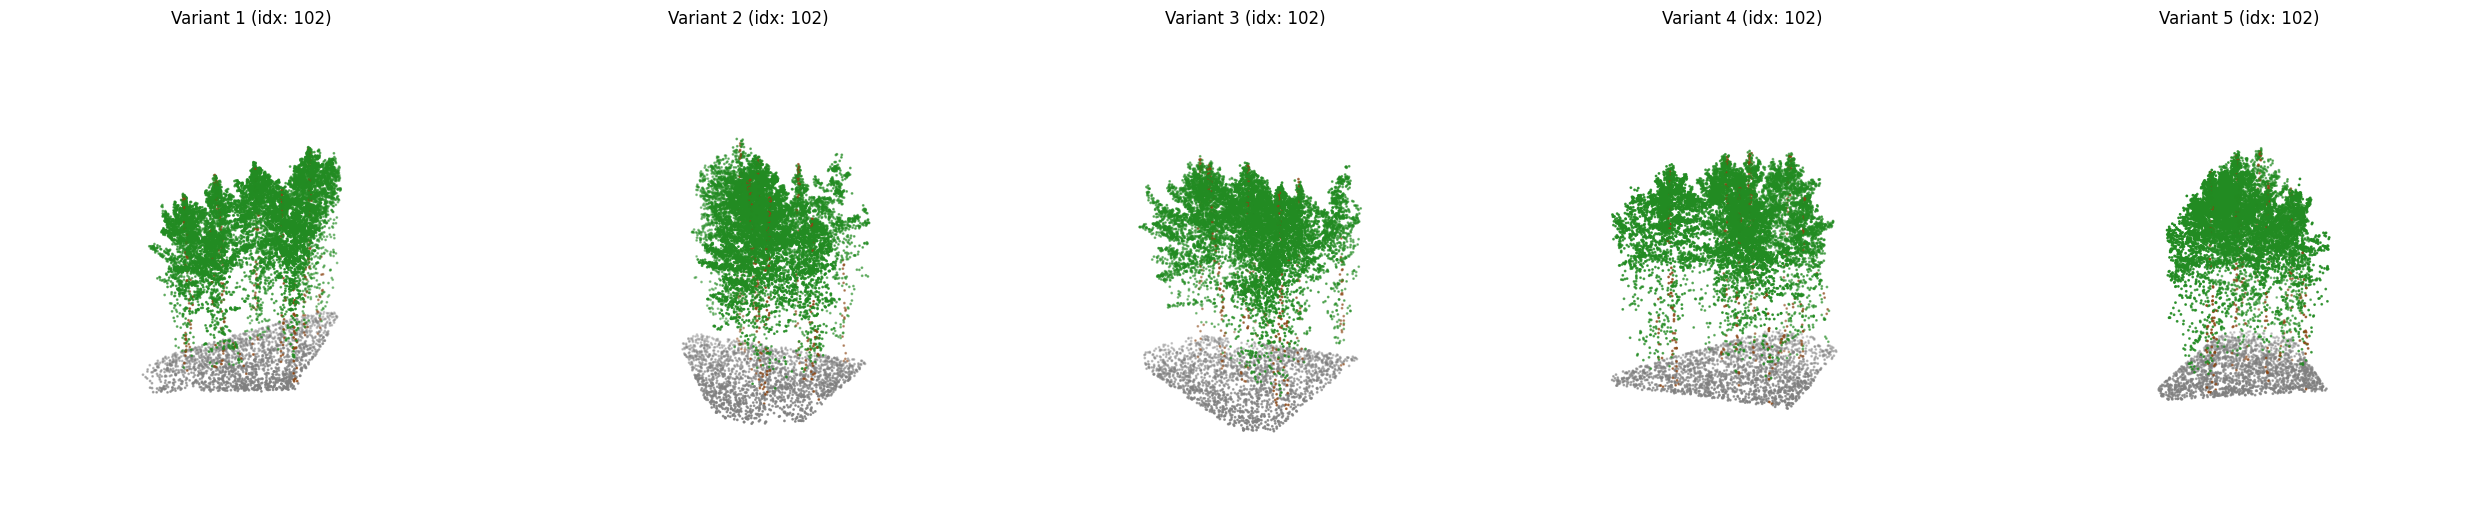

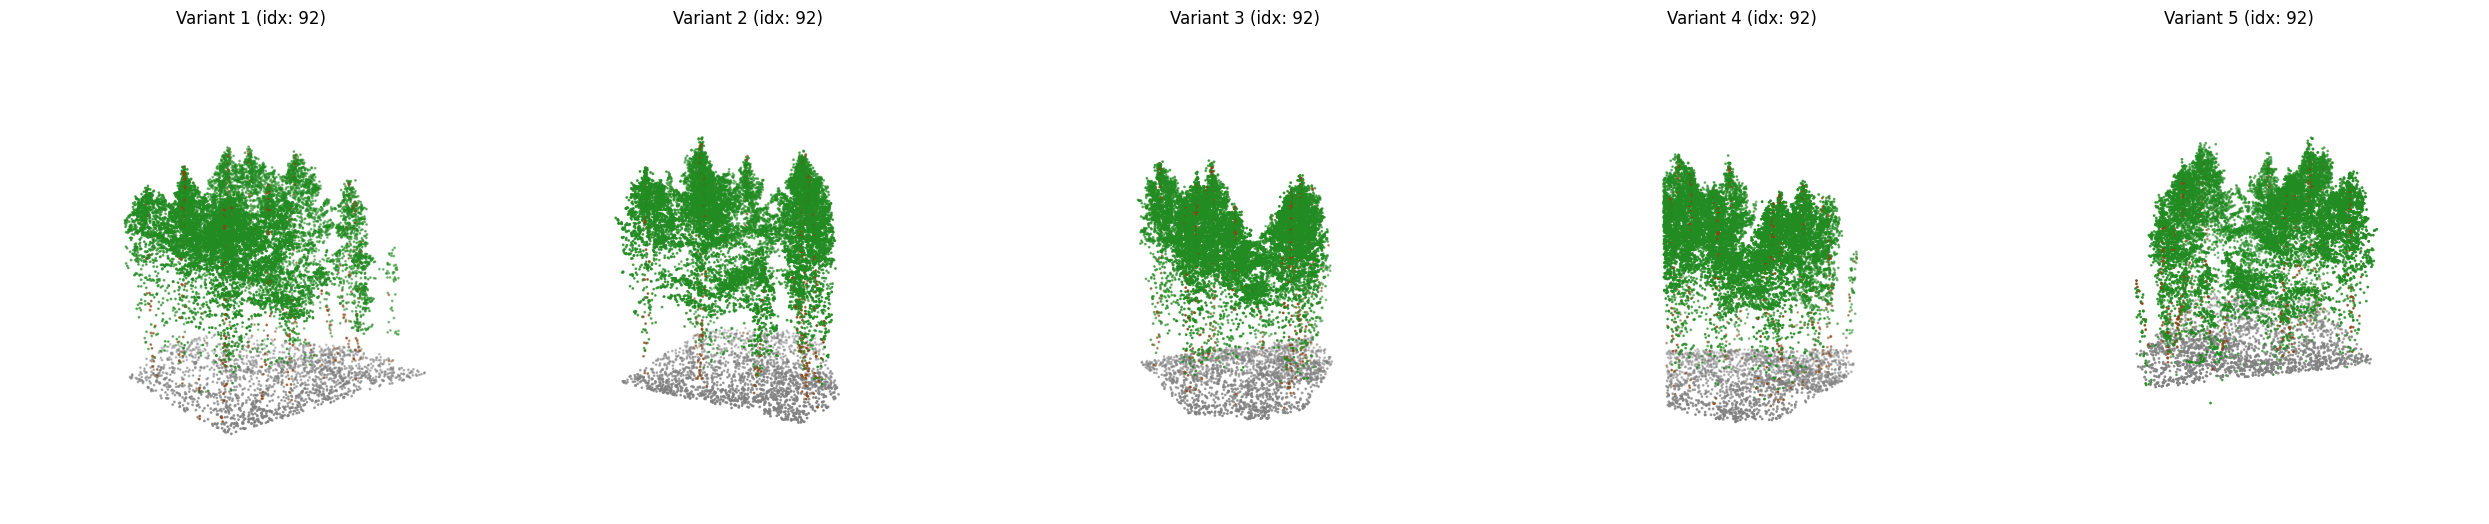

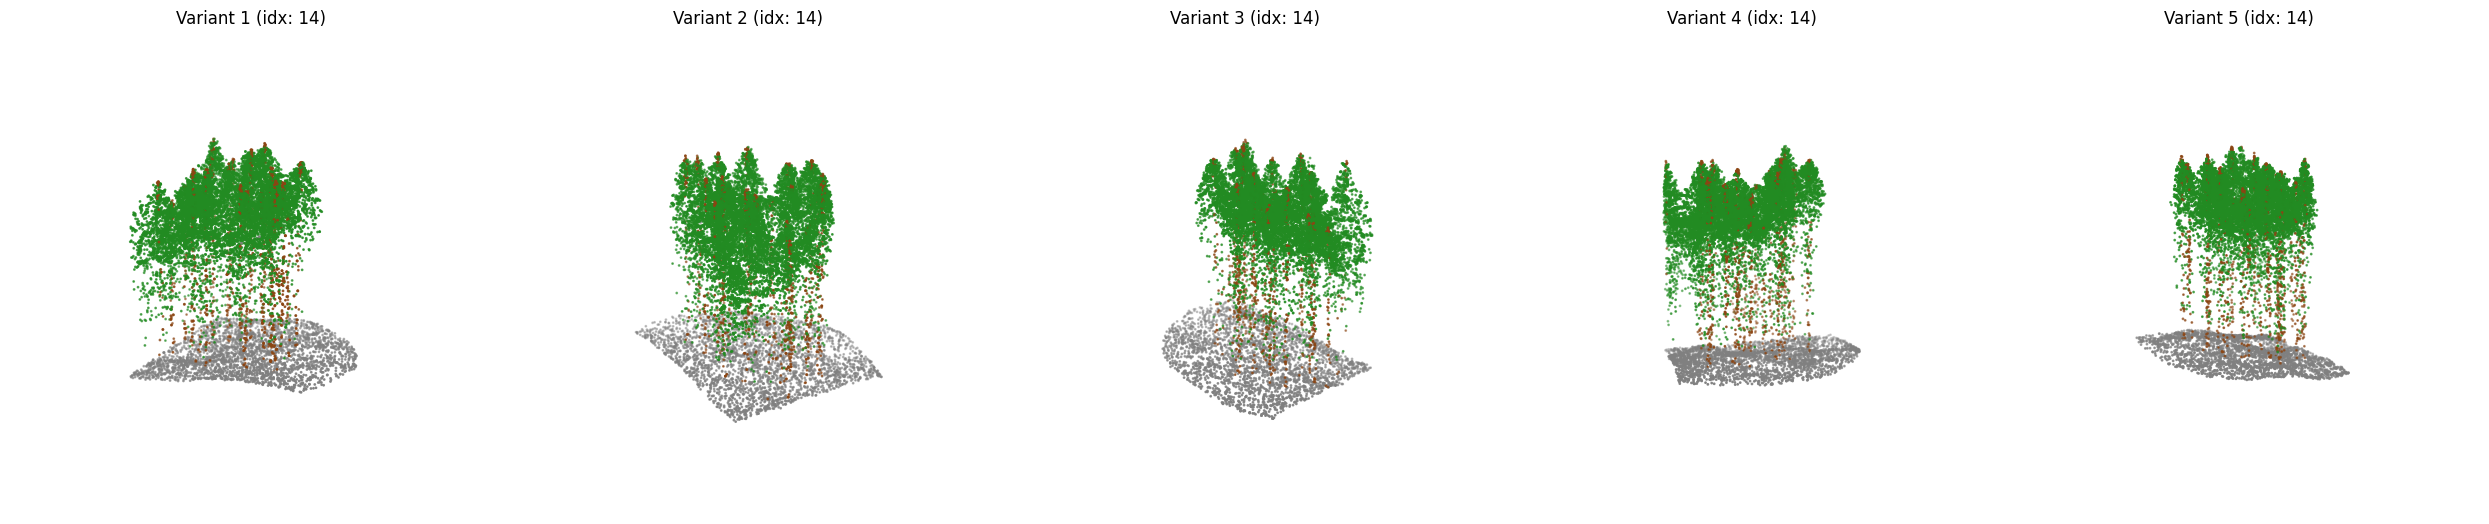

In [45]:
for i in range(3):
   visualize_augmentations(
       train_dataset, 
       sample_idx=np.random.randint(len(train_dataset)), 
       color_map=CFG.dataset.color_map,
       num_variants=5)

## Class Weights

In [46]:
if hasattr(CFG.dataset.class_names, "__dict__"):
    CFG.dataset.num_classes = len(vars(CFG.dataset.class_names))
    class_items = vars(CFG.dataset.class_names).items()
else:
    CFG.dataset.num_classes = len(CFG.dataset.class_names)
    class_items = CFG.dataset.class_names.items()

class_weights = calculate_class_weights(train_dataset)

for name, idx in class_items:
    print(f"Class: {name:<12} | Weight: {class_weights[idx]:.4f}")

Calculating class weights from dataset...
Class: background   | Weight: 1.1397
Class: trunk        | Weight: 7.4855
Class: tree_crown   | Weight: 0.5028


## Model Selection

In [47]:
model_name = CFG.model.active
model_params = vars(CFG.model.params)

print(f"Initializing Model Architecture: {model_name}...")

if model_name == "PointNetPP":
    model = PointNetPPModel(**model_params).to(device)

elif model_name == "PointNext":
    model = PointNextModel(**model_params).to(device)

elif model_name == "SpConv":
    if not SPCONV_AVAILABLE:
        raise ImportError("Cannot run SpConvModel: library not installed.")
    model = SpConvModel(**model_params).to(device)

elif model_name == "PTv3":
    if not PTv3_AVAILABLE:
        raise ImportError("PTv3 (Pointcept) not found! Ensure Step 9 & 10 are completed correctly.")
    model = PTv3Model(**model_params).to(device)

else:
    raise ValueError(f"Model architecture '{model_name}' is not recognized.")

Initializing Model Architecture: SpConv...


In [48]:
# Check of the model
print(f"{model_name} initialized successfully on {device}.")
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {n_params:,}")

SpConv initialized successfully on cuda.
Total trainable parameters: 7,089,443


## Loss Function

In [49]:
criterion_name = CFG.loss.name
criterion_params = vars(CFG.loss.params)

print(f"Initializing Loss Function: {criterion_name}...")

if criterion_name == "DiceFocalLoss":
    criterion = DiceFocalLoss(weight=class_weights, **criterion_params).to(device)
else:
    criterion_class = getattr(torch.nn, criterion_name)
    try:
        criterion = criterion_class(weight=class_weights, **criterion_params).to(device)
    except TypeError:
        criterion = criterion_class(**criterion_params).to(device)

print(f"Loss initialized successfully.")

Initializing Loss Function: DiceFocalLoss...
Loss initialized successfully.


## Optimizer

In [50]:
optimizer_name = CFG.optimizer.name
opt_params = {k: v for k, v in vars(CFG.optimizer).items() if k not in ['name', 'scheduler']}

optimizer_class = getattr(torch.optim, optimizer_name)
optimizer = optimizer_class(model.parameters(), **opt_params)

print(f"Optimizer: {optimizer_name} initialized with params: {opt_params}")

Optimizer: AdamW initialized with params: {'lr': 0.0001, 'weight_decay': 0.0001}


## Scheduler

In [51]:
scheduler_cfg = {
    "name": CFG.optimizer.scheduler.name,
    "params": {k: v for k, v in vars(CFG.optimizer.scheduler).items() if k != 'name'}
}

scheduler = get_scheduler(
    optimizer=optimizer,
    scheduler_config=scheduler_cfg,
    warmup_epochs=CFG.train.warmup_epochs
)

Created Sequential Scheduler: Warmup (5 ep) -> CosineAnnealingLR


## Logger

In [ ]:
class_names_inv = CFG.dataset.class_names_inv

CFG_DICT["system"]["log_dir"] = CFG.system.log_dir

setup_logging_session(CFG_DICT["logging"])

logger = ForestLogger(
    config_dict=CFG_DICT,
    class_names_inv=class_names_inv
)

print(f"Logger initialized as: {CFG.logging.logger.upper()}")
if CFG.logging.logger.lower() == "tensorboard":
    print(f"Local log path: {CFG.system.log_dir}")

## Training

In [53]:
num_classes = CFG.dataset.num_classes

metrics_collection = MetricCollection({
    "iou": MulticlassJaccardIndex(num_classes=num_classes, average=None),
    "f1": MulticlassF1Score(num_classes=num_classes, average=None),
    "precision": MulticlassPrecision(num_classes=num_classes, average=None),
    "recall": MulticlassRecall(num_classes=num_classes, average=None)
}).to(device)

print(f"Metrics collection initialized for {num_classes} classes.")

Metrics collection initialized for 3 classes.


In [54]:
# ==========================================================
# MAIN EXECUTION RUNNER (Optimized Console Output)
# ==========================================================

# 1. Setup metadata and fixed indices for visual monitoring
class_names_inv = CFG.dataset.class_names_inv
best_metric_val = 0.0
start_epoch = 0

# Select random but fixed indices for visualization consistency
indices_to_vis = np.random.choice(len(val_dataset), CFG.logging.num_vis, replace=False).tolist()

# 2. Resume logic
if CFG.train.resume:
    start_epoch, best_metric_val = load_checkpoint(
        CFG.train.path_to_ckpt, 
        model, 
        optimizer, 
        scheduler
    )
    start_epoch += 1

print(f"Starting Experiment: {CFG.system.exp_name}")
print(f"Tracking: {CFG.train.primary_metric} | Monitoring: {indices_to_vis}")

for epoch in range(start_epoch, CFG.train.epochs):

    # --- A. TRAINING & VALIDATION ---
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device, metrics_collection)

    # --- B. COMPUTE METRICS ---
    computed = metrics_collection.compute()
    mIoU = computed["iou"].mean().item()

    # --- C. LOGGING PACKAGE ASSEMBLY (FULL DATA for WandB/TB) ---
    logs = {
        "train/loss": train_loss,
        "train/accuracy": train_acc,
        "val/loss": val_loss,
        "val/accuracy": val_acc,
        "val/mIoU": mIoU,
        "val/mF1": computed["f1"].mean().item(),
        "charts/learning_rate": optimizer.param_groups[0]['lr']
    }
    # Add all per-class details to backends only
    for class_name, class_id in vars(CFG.dataset.class_names).items():
        logs[f"val_class_iou/{class_name}"] = computed["iou"][class_id].item()

    # --- D. EXECUTE LOGGING (WandB / TensorBoard) ---
    logger.log_metrics(logs, step=epoch)

    # --- E. VISUAL PROGRESS LOGGING ---
    if epoch % CFG.logging.vis_freq == 0:
        fig = generate_prediction_grid(
            val_dataset, model, device, CFG.dataset.color_map, indices=indices_to_vis
        )
        logger.log_figure("val/visual_comparisons", fig, step=epoch, save_dir=CFG.system.vis_dir)
        plt.close(fig)

    # --- F. COMPACT CONSOLE OUTPUT ---
    # Only general info on one line for better scrollability
    summary_msg = (f"Epoch {epoch:03d} | "
                   f"Loss (T/V): {train_loss:.4f}/{val_loss:.4f} | "
                   f"mIoU: {mIoU:.4f} | "
                   f"Acc (V): {val_acc:.4f}")

    # --- G. CHECKPOINTING LOGIC ---
    current_val = logs.get(CFG.train.primary_metric, 0.0)
    is_best = current_val > best_metric_val

    if is_best:
        best_metric_val = current_val
        summary_msg += f" | BEST ({CFG.train.primary_metric.split('/')[-1]})"

    print(summary_msg)

    # Save state
    save_checkpoint({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'miou': mIoU,
        'metrics': logs
    }, is_best, CFG.system.checkpoint_dir, CFG.system.exp_name)

    # Update learning rate
    scheduler.step()

# Cleanup
logger.finish()
print("Training completed.")

Starting Experiment: SpConv_v1
Tracking: val/mIoU | Monitoring: [8, 16, 0]


Training:   0%|          | 0/19 [00:00<?, ?it/s]

Validation:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 000 | Loss (T/V): 0.7156/0.7355 | mIoU: 0.0700 | Acc (V): 0.1863 | BEST (mIoU)
Best model saved with mIoU: 0.0700


Training:   0%|          | 0/19 [00:00<?, ?it/s]

Validation:   0%|          | 0/3 [00:00<?, ?it/s]

... (54 outputs left out)

Validation:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 019 | Loss (T/V): 0.3545/0.3729 | mIoU: 0.7294 | Acc (V): 0.9212


charts/learning_rate,▂▃▄▅▇███▇▇▆▆▅▄▃▃▂▂▁▁
train/accuracy,▁▃▅▆▇▇▇█████████████
train/loss,█▆▅▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁
val/accuracy,▁▃▇▇▇█▇████▇████████
val/loss,█▆▄▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁
val/mF1,▁▄▇▇▇█▇█████████████
val/mIoU,▁▃▆▇▇█▇████▇████████
val_class_iou/background,▁▃▇█████████████████
val_class_iou/tree_crown,▁▃▇▇▇█▇████▇████████
val_class_iou/trunk,▁▃▄▄▄▆▄▆▆▇█▆▇▇▇█████
charts/learning_rate,0.0


Logger session finalized.
Training completed.


## Final Evaluation & Analysis

Loaded best model from epoch 10 (mIoU: 0.7361)



CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  background     0.9921    0.9581    0.9748    164439
       trunk     0.3782    0.6950    0.4898     32232
  tree_crown     0.9771    0.9375    0.9569    526746

    accuracy                         0.9314    723417
   macro avg     0.7825    0.8635    0.8072    723417
weighted avg     0.9538    0.9314    0.9401    723417



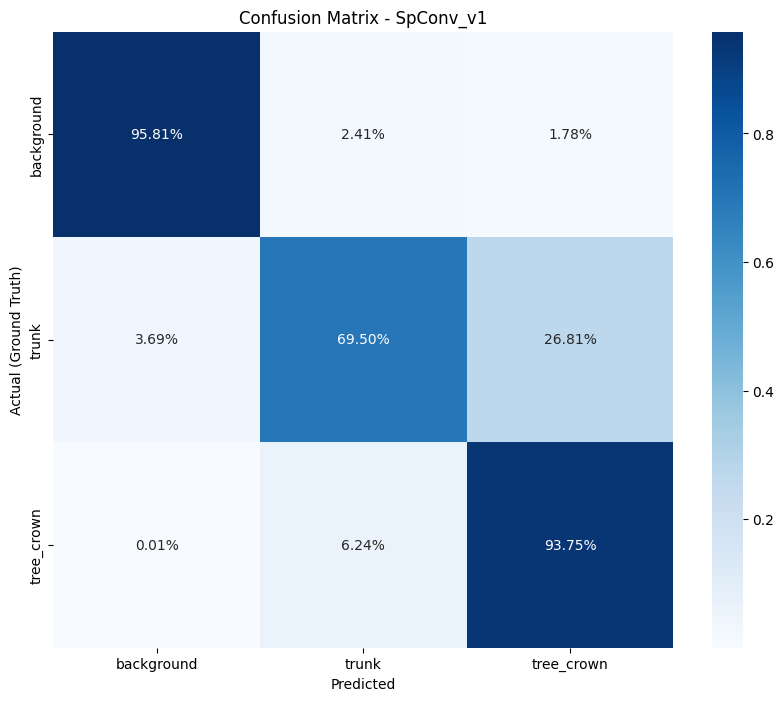

In [55]:
# 1. Load the best weights
checkpoint_path = os.path.join(CFG.system.checkpoint_dir, f"{CFG.system.exp_name}_best.pth")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch']} (mIoU: {checkpoint['miou']:.4f})")

# 2. Get predictions for the whole validation set
y_true, y_pred = get_all_predictions(model, test_loader, device)

# 3. Generate Classification Report
# Robustly get class count and names from CFG
num_classes = len(vars(CFG.dataset.class_names))
target_names = [CFG.dataset.class_names_inv[i] for i in range(num_classes)]
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# 4. Generate Confusion Matrix Visualization
cm = confusion_matrix(y_true, y_pred, normalize='true') 

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='.2%', xticklabels=target_names, yticklabels=target_names, cmap='Blues')
plt.title(f"Confusion Matrix - {CFG.system.exp_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual (Ground Truth)")

# 5. Save matrix to the correct visualization folder
plt.savefig(os.path.join(CFG.system.vis_dir, "final_confusion_matrix.png"), bbox_inches='tight')
plt.show()

## Prediction Visualisation

Generating final visualizations for samples: [35, 12, 4, 23]


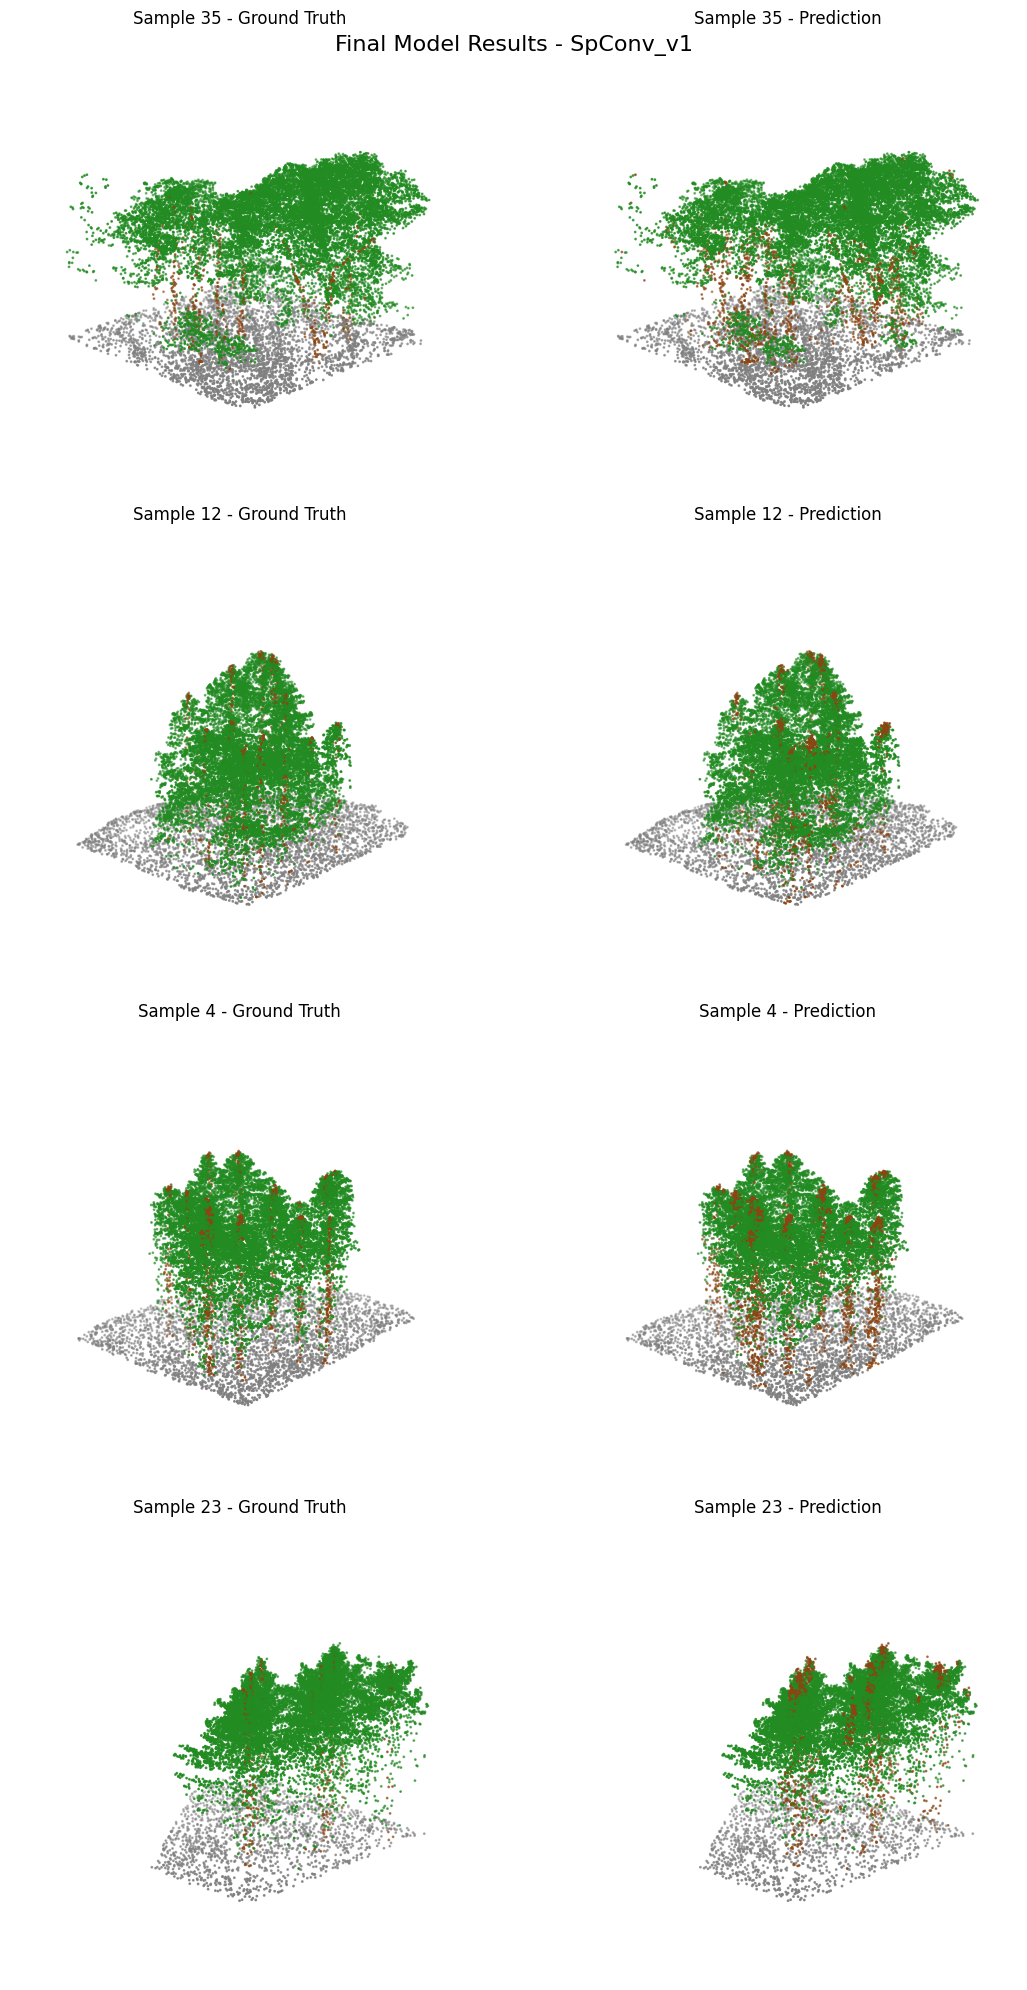

In [56]:
num_final_vis = 4
final_indices = np.random.choice(len(test_dataset), num_final_vis, replace=False).tolist()

print(f"Generating final visualizations for samples: {final_indices}")

fig_final = generate_prediction_grid(
    test_dataset,
    model,
    device,
    CFG.dataset.color_map,
    indices=final_indices
)

plt.suptitle(f"Final Model Results - {CFG.system.exp_name}", fontsize=16)
plt.show()

## Inference And Export

In [57]:
run_inference_and_export(
    model=model,
    dataloader=test_loader,
    device=device,
    output_dir=CFG.system.pred_dir
)

Starting inference. Results will be saved to: /notebooks/semantic_segmentation_results/SpConv_v1/predictions


Exporting NPZ:   0%|          | 0/6 [00:00<?, ?it/s]

Export completed. Files saved in /notebooks/semantic_segmentation_results/SpConv_v1/predictions
